# Fase 5 (versión Kaggle) — Entrenamiento de la U-Net base

**Cómo correrlo en segundo plano:**
1. Panel derecho → *Session options* → **Accelerator: GPU T4 x2** · **Internet: On** (requiere cuenta verificada con teléfono).
2. Arriba a la derecha → **Save Version** → **Save & Run All (Commit)** → *Save*.
3. Puedes cerrar el navegador. Ves el avance en *View Active Events*; al terminar, la pestaña **Output** tiene `rnap_p2_inundaciones/` (resultados, figuras y checkpoints) para descargar.

Este notebook es **autocontenido**: escribe todos los módulos de `src/` (idénticos a los de Colab salvo `configuracion.py` y `descarga.py`, adaptados a Kaggle) y baja los datos solo.

## 0. Dependencias y GPU

In [1]:
!pip install -q rasterio google-cloud-storage
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


## 1. Módulos de `src/`

In [2]:
from pathlib import Path
(Path('/kaggle/working/rnap_p2_inundaciones') / 'src').mkdir(parents=True, exist_ok=True)
(Path('/kaggle/working/rnap_p2_inundaciones') / 'src' / '__init__.py').touch()

In [3]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/configuracion.py
"""
configuracion.py  (VERSIÓN KAGGLE)
Mismas constantes que la versión de Colab; solo cambian las rutas raíz.
  - /kaggle/working  -> se guarda como "Output" del notebook al terminar (resultados, checkpoints, figuras)
  - /tmp             -> disco temporal para los datos (no infla el Output)
"""
from pathlib import Path

RAIZ_PROYECTO = Path("/kaggle/working/rnap_p2_inundaciones")
RAIZ_DATOS = Path("/tmp/datos_sen1floods11")
BUCKET = "gs://sen1floods11/v1.1"

DIR_S1_MANO        = RAIZ_DATOS / "HandLabeled" / "S1Hand"
DIR_ETIQUETA_MANO  = RAIZ_DATOS / "HandLabeled" / "LabelHand"
DIR_OTSU_MANO      = RAIZ_DATOS / "HandLabeled" / "S1OtsuLabelHand"
DIR_S2_MANO        = RAIZ_DATOS / "HandLabeled" / "S2Hand"
DIR_S1_DEBIL       = RAIZ_DATOS / "WeaklyLabeled" / "S1Weak"
DIR_ETIQUETA_DEBIL = RAIZ_DATOS / "WeaklyLabeled" / "S1OtsuLabelWeak"
DIR_PARTICIONES    = RAIZ_DATOS / "splits" / "flood_handlabeled"

DIR_RESULTADOS  = RAIZ_PROYECTO / "resultados"
DIR_CHECKPOINTS = RAIZ_PROYECTO / "checkpoints"
DIR_FIGURAS     = RAIZ_PROYECTO / "figuras"

VALOR_SIN_DATO = -1
TAMANO_CHIP = 512
SEMILLA = 42


Writing /kaggle/working/rnap_p2_inundaciones/src/configuracion.py


In [4]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/utilidades.py
"""
utilidades.py
Funciones transversales: reproducibilidad y dispositivo.
"""
import os
import random

import numpy as np
import torch


def fijar_semilla(semilla: int = 42) -> None:
    """Fija todas las fuentes de aleatoriedad para que los experimentos sean repetibles
    (clave en el estudio de ablación: si cambia el resultado, que sea por la decisión, no por azar)."""
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)
    os.environ["PYTHONHASHSEED"] = str(semilla)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def obtener_dispositivo() -> torch.device:
    dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if dispositivo.type == "cuda":
        print(f"GPU: {torch.cuda.get_device_name(0)}")
    else:
        print("OJO: sin GPU. En Colab: Entorno de ejecución > Cambiar tipo > T4 GPU")
    return dispositivo


Writing /kaggle/working/rnap_p2_inundaciones/src/utilidades.py


In [5]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/descarga.py
"""
descarga.py  (VERSIÓN KAGGLE)
Kaggle no trae gsutil: se usa el cliente Python de Google Cloud Storage en modo ANÓNIMO
(el bucket es público) y se descarga en paralelo con hilos.
"""
from concurrent.futures import ThreadPoolExecutor

from google.cloud import storage
from tqdm.auto import tqdm

from .configuracion import (DIR_S1_MANO, DIR_ETIQUETA_MANO, DIR_OTSU_MANO, DIR_S2_MANO,
                            DIR_S1_DEBIL, DIR_ETIQUETA_DEBIL, DIR_PARTICIONES)

NOMBRE_BUCKET, VERSION = "sen1floods11", "v1.1"
_ORIGENES = {
    DIR_S1_MANO:        "data/flood_events/HandLabeled/S1Hand",
    DIR_ETIQUETA_MANO:  "data/flood_events/HandLabeled/LabelHand",
    DIR_OTSU_MANO:      "data/flood_events/HandLabeled/S1OtsuLabelHand",
    DIR_PARTICIONES:    "splits/flood_handlabeled",
    DIR_S2_MANO:        "data/flood_events/HandLabeled/S2Hand",
    DIR_S1_DEBIL:       "data/flood_events/WeaklyLabeled/S1Weak",
    DIR_ETIQUETA_DEBIL: "data/flood_events/WeaklyLabeled/S1OtsuLabelWeak",
}


def _descargar(destino, hilos: int = 16) -> None:
    if destino.exists() and any(destino.iterdir()):
        print(f"[ya existe] {destino.name}")
        return
    destino.mkdir(parents=True, exist_ok=True)
    cliente = storage.Client.create_anonymous_client()
    prefijo = f"{VERSION}/{_ORIGENES[destino]}/"
    blobs = [b for b in cliente.list_blobs(NOMBRE_BUCKET, prefix=prefijo) if not b.name.endswith("/")]

    def bajar(blob):
        blob.download_to_filename(str(destino / blob.name.split("/")[-1]))

    with ThreadPoolExecutor(hilos) as ejecutor:
        list(tqdm(ejecutor.map(bajar, blobs), total=len(blobs), desc=destino.name))


def descargar_mano() -> None:
    for destino in [DIR_S1_MANO, DIR_ETIQUETA_MANO, DIR_OTSU_MANO, DIR_PARTICIONES]:
        _descargar(destino)


def descargar_debil() -> None:
    for destino in [DIR_S1_DEBIL, DIR_ETIQUETA_DEBIL]:
        _descargar(destino)


def descargar_s2_mano() -> None:
    _descargar(DIR_S2_MANO)


Writing /kaggle/working/rnap_p2_inundaciones/src/descarga.py


In [6]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/lectura.py
"""
lectura.py
Lectura de particiones y de chips GeoTIFF de Sen1Floods11.
Convención de nombres: {Evento}_{idChip}_{Capa}.tif   ej. Bolivia_103757_S1Hand.tif
"""
import numpy as np
import pandas as pd
import rasterio

from .configuracion import DIR_PARTICIONES, DIR_S1_MANO, DIR_ETIQUETA_MANO, DIR_OTSU_MANO

PARTICIONES = ["train", "valid", "test", "bolivia"]


def leer_particion(nombre: str) -> pd.DataFrame:
    """Devuelve un DataFrame con id_chip, evento y partición a partir del CSV oficial."""
    ruta = DIR_PARTICIONES / f"flood_{nombre}_data.csv"
    df = pd.read_csv(ruta, header=None, names=["archivo_s1", "archivo_etiqueta"])
    df["id_chip"] = df["archivo_s1"].str.replace("_S1Hand.tif", "", regex=False)
    df["evento"] = df["id_chip"].str.split("_").str[0]
    df["particion"] = nombre
    return df[["id_chip", "evento", "particion"]]


def leer_todas_las_particiones() -> pd.DataFrame:
    return pd.concat([leer_particion(p) for p in PARTICIONES], ignore_index=True)


def leer_tif(ruta) -> np.ndarray:
    with rasterio.open(ruta) as src:
        return src.read()          # (bandas, alto, ancho)


def leer_s1(id_chip: str, carpeta=DIR_S1_MANO, sufijo: str = "S1Hand") -> np.ndarray:
    """SAR Sentinel-1: (2, 512, 512) float32 -> banda 0 = VV, banda 1 = VH, en dB."""
    return leer_tif(carpeta / f"{id_chip}_{sufijo}.tif").astype(np.float32)


def leer_etiqueta(id_chip: str, carpeta=DIR_ETIQUETA_MANO, sufijo: str = "LabelHand") -> np.ndarray:
    """Máscara (512, 512) int16: -1 sin dato, 0 no agua, 1 agua."""
    return leer_tif(carpeta / f"{id_chip}_{sufijo}.tif")[0].astype(np.int16)


def leer_otsu(id_chip: str) -> np.ndarray:
    """Etiqueta automática por umbral de Otsu sobre el MISMO chip (la 'etiqueta débil')."""
    return leer_etiqueta(id_chip, DIR_OTSU_MANO, "S1OtsuLabelHand")


Writing /kaggle/working/rnap_p2_inundaciones/src/lectura.py


In [7]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/metricas.py
"""
metricas.py
Métricas de segmentación binaria para la clase "agua" a partir de conteos de la matriz de confusión.
Siempre se calculan SOLO sobre píxeles válidos (etiqueta != -1).
"""
import numpy as np


def conteos_confusion(prediccion: np.ndarray, referencia: np.ndarray, validos: np.ndarray) -> dict:
    """prediccion/referencia: arrays binarios {0,1}; validos: máscara booleana."""
    p = prediccion[validos].astype(bool)
    r = referencia[validos].astype(bool)
    return {
        "vp": int(np.sum(p & r)),     # verdaderos positivos (agua bien detectada)
        "fp": int(np.sum(p & ~r)),    # falsos positivos (dice agua y no es)
        "fn": int(np.sum(~p & r)),    # falsos negativos (agua no detectada)
        "vn": int(np.sum(~p & ~r)),   # verdaderos negativos
    }


def metricas_desde_conteos(vp: int, fp: int, fn: int, vn: int) -> dict:
    eps = 1e-9
    precision = vp / (vp + fp + eps)
    recall = vp / (vp + fn + eps)
    return {
        "iou": vp / (vp + fp + fn + eps),
        "f1": 2 * precision * recall / (precision + recall + eps),
        "precision": precision,
        "recall": recall,
        "omision": fn / (vp + fn + eps),     # = 1 - recall   (agua que se nos escapó)
        "comision": fp / (vp + fp + eps),    # = 1 - precision (agua inventada)
        "exactitud": (vp + vn) / (vp + fp + fn + vn + eps),
    }


Writing /kaggle/working/rnap_p2_inundaciones/src/metricas.py


In [8]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/metricas_torch.py
"""
metricas_torch.py
Acumulador de la matriz de confusión durante la evaluación (en GPU, sin copiar píxeles a CPU).
Clave: las métricas se calculan con los conteos SUMADOS de todos los chips (IoU agregado),
no promediando IoU chip por chip -> los chips sin agua (26 en Ghana) no producen 0/0.
También acumula por evento, para el desglose del informe.
"""
from collections import defaultdict

import numpy as np
import pandas as pd
import torch

from .metricas import metricas_desde_conteos

VALOR_IGNORAR = -1


class AcumuladorConfusion:
    def __init__(self, umbral: float = 0.5):
        self.umbral = umbral
        self.reiniciar()

    def reiniciar(self):
        self.global_ = torch.zeros(4, dtype=torch.int64)           # vp, fp, fn, vn
        self.por_evento = defaultdict(lambda: torch.zeros(4, dtype=torch.int64))

    @torch.no_grad()
    def actualizar(self, logits, etiquetas, ids_chips=None):
        if logits.dim() == 4:
            logits = logits.squeeze(1)
        prediccion = torch.sigmoid(logits.float()) > self.umbral
        referencia = etiquetas == 1
        validos = etiquetas != VALOR_IGNORAR
        # conteos por chip (dim 1,2 = alto, ancho) -> (B, 4)
        conteos = torch.stack([
            (prediccion & referencia & validos).sum(dim=(1, 2)),
            (prediccion & ~referencia & validos).sum(dim=(1, 2)),
            (~prediccion & referencia & validos).sum(dim=(1, 2)),
            (~prediccion & ~referencia & validos).sum(dim=(1, 2)),
        ], dim=1).cpu()
        self.global_ += conteos.sum(dim=0)
        if ids_chips is not None:
            for id_chip, fila in zip(ids_chips, conteos):
                self.por_evento[id_chip.split("_")[0]] += fila

    def metricas(self) -> dict:
        return metricas_desde_conteos(*self.global_.tolist())

    def matriz_confusion(self) -> np.ndarray:
        """[[VN, FP], [FN, VP]]  (filas = real no agua / agua; columnas = predicho no agua / agua)."""
        vp, fp, fn, vn = self.global_.tolist()
        return np.array([[vn, fp], [fn, vp]], dtype=np.int64)

    def tabla_por_evento(self) -> pd.DataFrame:
        filas = {evento: metricas_desde_conteos(*c.tolist()) for evento, c in self.por_evento.items()}
        return pd.DataFrame(filas).T.sort_values("iou")


Writing /kaggle/working/rnap_p2_inundaciones/src/metricas_torch.py


In [9]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/preprocesamiento.py
"""
preprocesamiento.py
Normalización de las bandas SAR (VV, VH) con las estadísticas calculadas SOLO en train (fase 1).
Pasos:  1) detectar píxeles no finitos (NaN/inf)
        2) recortar a [p1, p99]  -> evita que valores extremos dominen
        3) estandarizar (x - media) / desviacion  -> entradas centradas en 0 y escala ~1
        4) NaN -> 0 (que tras estandarizar = "valor medio": la red no recibe basura)
"""
import json

import numpy as np

BANDAS = ["vv", "vh"]


class Normalizador:
    def __init__(self, estadisticas: dict):
        self.minimos = np.array([estadisticas[b]["p1"] for b in BANDAS], dtype=np.float32)[:, None, None]
        self.maximos = np.array([estadisticas[b]["p99"] for b in BANDAS], dtype=np.float32)[:, None, None]
        self.medias = np.array([estadisticas[b]["media"] for b in BANDAS], dtype=np.float32)[:, None, None]
        self.desviaciones = np.array([estadisticas[b]["desviacion"] for b in BANDAS], dtype=np.float32)[:, None, None]

    @classmethod
    def desde_json(cls, ruta) -> "Normalizador":
        with open(ruta) as f:
            return cls(json.load(f))

    def __call__(self, s1: np.ndarray):
        """s1: (2, H, W) en dB -> (s1 normalizado (2, H, W), máscara de píxeles finitos (H, W))."""
        finitos = np.isfinite(s1).all(axis=0)
        x = np.clip(s1, self.minimos, self.maximos)
        x = (x - self.medias) / self.desviaciones
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
        return x.astype(np.float32), finitos

    def revertir(self, x: np.ndarray) -> np.ndarray:
        """De vuelta a dB (útil para visualizar lo que entra a la red)."""
        return x * self.desviaciones + self.medias


Writing /kaggle/working/rnap_p2_inundaciones/src/preprocesamiento.py


In [10]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/aumentos.py
"""
aumentos.py
Aumento de datos geométrico. Regla de oro en segmentación: la MISMA transformación
a la imagen y a la máscara, si no la etiqueta deja de corresponder al píxel.

Solo usamos volteos y rotaciones de 90°: no inventan valores (no hay interpolación),
así que la máscara sigue siendo exactamente {-1, 0, 1}.
Matiz para el informe: el SAR mira de lado (geometría oblicua), por lo que la dirección
de sombras/layover no es invariante a rotaciones; aun así es la práctica estándar
y mejora la generalización con pocos datos (446 chips).
"""
import numpy as np


def aumentar(imagen: np.ndarray, etiqueta: np.ndarray, generador: np.random.Generator):
    """imagen: (C, H, W); etiqueta: (H, W)."""
    if generador.random() < 0.5:                       # volteo horizontal
        imagen, etiqueta = imagen[:, :, ::-1], etiqueta[:, ::-1]
    if generador.random() < 0.5:                       # volteo vertical
        imagen, etiqueta = imagen[:, ::-1, :], etiqueta[::-1, :]
    k = int(generador.integers(0, 4))                  # rotación 0/90/180/270
    if k:
        imagen = np.rot90(imagen, k, axes=(1, 2))
        etiqueta = np.rot90(etiqueta, k, axes=(0, 1))
    return np.ascontiguousarray(imagen), np.ascontiguousarray(etiqueta)


def recorte_aleatorio(imagen: np.ndarray, etiqueta: np.ndarray, tamano: int, generador: np.random.Generator):
    """Recorta una ventana tamano x tamano en posición aleatoria (otra forma de aumento)."""
    _, alto, ancho = imagen.shape
    fila = int(generador.integers(0, alto - tamano + 1))
    columna = int(generador.integers(0, ancho - tamano + 1))
    return (imagen[:, fila:fila + tamano, columna:columna + tamano],
            etiqueta[fila:fila + tamano, columna:columna + tamano])


Writing /kaggle/working/rnap_p2_inundaciones/src/aumentos.py


In [11]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/conjunto_datos.py
"""
conjunto_datos.py
Dataset de PyTorch para Sen1Floods11.
Devuelve (imagen, etiqueta, id_chip):
  imagen   : tensor float32 (2, H, W)  -> VV, VH normalizados
  etiqueta : tensor int64   (H, W)     -> 0 no agua, 1 agua, -1 IGNORAR (sin dato o SAR no finito)
"""
import numpy as np
import torch
from torch.utils.data import Dataset
from tqdm.auto import tqdm

from .aumentos import aumentar, recorte_aleatorio
from .configuracion import VALOR_SIN_DATO, DIR_S1_MANO, DIR_ETIQUETA_MANO
from .lectura import leer_s1, leer_etiqueta


class ConjuntoInundaciones(Dataset):
    def __init__(self, ids_chips, normalizador, aumentar_datos: bool = False,
                 tamano_recorte: int | None = None, en_memoria: bool = True,
                 dir_s1=DIR_S1_MANO, sufijo_s1: str = "S1Hand",
                 dir_etiqueta=DIR_ETIQUETA_MANO, sufijo_etiqueta: str = "LabelHand",
                 semilla: int = 42):
        self.ids_chips = list(ids_chips)
        self.normalizador = normalizador
        self.aumentar_datos = aumentar_datos
        self.tamano_recorte = tamano_recorte
        self.dir_s1, self.sufijo_s1 = dir_s1, sufijo_s1
        self.dir_etiqueta, self.sufijo_etiqueta = dir_etiqueta, sufijo_etiqueta
        self.generador = np.random.default_rng(semilla)

        # Los chips a mano caben en RAM (~2 MB c/u): se cargan UNA vez, antes de que los
        # workers del DataLoader se creen (así lo comparten en vez de leer disco cada época).
        self.cache = None
        if en_memoria:
            self.cache = [self._cargar(i) for i in tqdm(self.ids_chips, desc="Cargando chips en RAM")]

    def _cargar(self, id_chip):
        s1 = leer_s1(id_chip, self.dir_s1, self.sufijo_s1)
        etiqueta = leer_etiqueta(id_chip, self.dir_etiqueta, self.sufijo_etiqueta)
        imagen, finitos = self.normalizador(s1)
        etiqueta = etiqueta.copy()
        etiqueta[~finitos] = VALOR_SIN_DATO          # SAR inválido -> no se evalúa ni se aprende
        return imagen, etiqueta.astype(np.int64)

    def __len__(self):
        return len(self.ids_chips)

    def __getitem__(self, indice):
        imagen, etiqueta = self.cache[indice] if self.cache is not None else self._cargar(self.ids_chips[indice])
        if self.tamano_recorte:
            imagen, etiqueta = recorte_aleatorio(imagen, etiqueta, self.tamano_recorte, self.generador)
        if self.aumentar_datos:
            imagen, etiqueta = aumentar(imagen, etiqueta, self.generador)
        return torch.from_numpy(np.ascontiguousarray(imagen)), \
               torch.from_numpy(np.ascontiguousarray(etiqueta)), self.ids_chips[indice]


def semilla_por_worker(id_worker: int):
    """Cada worker del DataLoader recibe su propio generador (si no, todos aumentarían igual)."""
    informacion = torch.utils.data.get_worker_info()
    semilla = (torch.initial_seed() + id_worker) % 2**32
    informacion.dataset.generador = np.random.default_rng(semilla)


Writing /kaggle/working/rnap_p2_inundaciones/src/conjunto_datos.py


In [12]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/cargadores.py
"""
cargadores.py
Crea los DataLoader de las 4 particiones oficiales de los chips a mano.
Solo 'train' lleva aumento de datos (y recorte opcional); valid/test/bolivia se evalúan tal cual.
"""
import torch
from torch.utils.data import DataLoader

from .conjunto_datos import ConjuntoInundaciones, semilla_por_worker
from .lectura import leer_particion


def crear_cargadores(normalizador, tamano_lote: int = 8, tamano_recorte: int | None = None,
                     num_workers: int = 2, semilla: int = 42) -> dict:
    cargadores = {}
    for particion in ["train", "valid", "test", "bolivia"]:
        es_train = particion == "train"
        ids = leer_particion(particion)["id_chip"]
        conjunto = ConjuntoInundaciones(ids, normalizador, aumentar_datos=es_train,
                                        tamano_recorte=tamano_recorte if es_train else None,
                                        semilla=semilla)
        cargadores[particion] = DataLoader(
            conjunto,
            batch_size=tamano_lote if es_train else max(1, tamano_lote // 2),
            shuffle=es_train,
            drop_last=es_train,              # evita un último lote de 1-2 chips (BatchNorm inestable)
            num_workers=num_workers,
            pin_memory=torch.cuda.is_available(),
            worker_init_fn=semilla_por_worker,
            generator=torch.Generator().manual_seed(semilla),
            persistent_workers=num_workers > 0,
        )
        print(f"{particion:8s}: {len(conjunto):3d} chips -> {len(cargadores[particion]):3d} lotes")
    return cargadores


Writing /kaggle/working/rnap_p2_inundaciones/src/cargadores.py


In [13]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/modelo_unet.py
"""
modelo_unet.py
U-Net implementada desde cero (Ronneberger et al., 2015), adaptada a SAR de 2 bandas.

Arquitectura (profundidad=4, canales_base=c):
  Entrada (2, H, W)
  ├─ Codificador  : DobleConv(2→c) → [MaxPool + DobleConv] x4  (c→2c→4c→8c→16c)   "qué hay"
  ├─ Decodificador: [ConvTranspuesta ×2 + concatenar salto + DobleConv] x4         "dónde está"
  └─ Cabeza 1x1   : c → 1 canal = logit de "agua" por píxel

Diferencias con el paper original (documentarlas en el informe):
  - padding=1 ("same"): la salida tiene el mismo tamaño que la entrada (el original recortaba).
  - BatchNorm tras cada convolución (no existía en 2015; estabiliza y acelera el entrenamiento).
  - 1 canal de salida con sigmoide (problema binario) en vez de 2 con softmax.
  - Parámetros configurables para la ablación: profundidad, canales_base y usar_saltos.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


class DobleConv(nn.Module):
    """(Conv 3x3 → BatchNorm → ReLU) x 2. Bloque básico de la U-Net."""

    def __init__(self, canales_entrada: int, canales_salida: int, abandono: float = 0.0):
        super().__init__()
        capas = [
            nn.Conv2d(canales_entrada, canales_salida, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(canales_salida),
            nn.ReLU(inplace=True),
            nn.Conv2d(canales_salida, canales_salida, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(canales_salida),
            nn.ReLU(inplace=True),
        ]
        if abandono > 0:
            capas.append(nn.Dropout2d(abandono))
        self.bloque = nn.Sequential(*capas)

    def forward(self, x):
        return self.bloque(x)


class Bajada(nn.Module):
    """MaxPool 2x2 (reduce resolución a la mitad) + DobleConv (duplica canales)."""

    def __init__(self, canales_entrada: int, canales_salida: int, abandono: float = 0.0):
        super().__init__()
        self.agrupar = nn.MaxPool2d(2)
        self.conv = DobleConv(canales_entrada, canales_salida, abandono)

    def forward(self, x):
        return self.conv(self.agrupar(x))


class Subida(nn.Module):
    """ConvTranspuesta 2x2 (duplica resolución) + concatenar el salto del codificador + DobleConv."""

    def __init__(self, canales_entrada: int, canales_salida: int, usar_salto: bool = True):
        super().__init__()
        self.usar_salto = usar_salto
        self.subir = nn.ConvTranspose2d(canales_entrada, canales_entrada // 2, kernel_size=2, stride=2)
        canales_conv = canales_entrada // 2 + (canales_salida if usar_salto else 0)
        self.conv = DobleConv(canales_conv, canales_salida)

    def forward(self, x, salto):
        x = self.subir(x)
        # si H o W no eran divisibles entre 2^profundidad, ajustamos con padding al tamaño del salto
        dif_alto, dif_ancho = salto.shape[2] - x.shape[2], salto.shape[3] - x.shape[3]
        if dif_alto or dif_ancho:
            x = F.pad(x, [dif_ancho // 2, dif_ancho - dif_ancho // 2, dif_alto // 2, dif_alto - dif_alto // 2])
        if self.usar_salto:
            x = torch.cat([salto, x], dim=1)   # detalle espacial fino (salto) + contexto (x)
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, canales_entrada: int = 2, canales_base: int = 32, profundidad: int = 4,
                 usar_saltos: bool = True, abandono: float = 0.0):
        super().__init__()
        self.configuracion = dict(canales_entrada=canales_entrada, canales_base=canales_base,
                                  profundidad=profundidad, usar_saltos=usar_saltos, abandono=abandono)
        canales = [canales_base * 2 ** i for i in range(profundidad + 1)]   # ej. 32, 64, 128, 256, 512

        self.entrada = DobleConv(canales_entrada, canales[0])
        # el abandono (dropout) solo en los niveles más profundos, donde hay más parámetros
        self.codificador = nn.ModuleList(
            Bajada(canales[i], canales[i + 1], abandono if i >= profundidad - 2 else 0.0)
            for i in range(profundidad)
        )
        self.decodificador = nn.ModuleList(
            Subida(canales[i + 1], canales[i], usar_saltos) for i in reversed(range(profundidad))
        )
        self.salida = nn.Conv2d(canales[0], 1, kernel_size=1)
        self._inicializar_pesos()

    def _inicializar_pesos(self):
        """He/Kaiming: pensada para ReLU, mantiene la varianza de las activaciones entre capas."""
        for modulo in self.modules():
            if isinstance(modulo, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(modulo.weight, mode="fan_out", nonlinearity="relu")
                if modulo.bias is not None:
                    nn.init.zeros_(modulo.bias)
            elif isinstance(modulo, nn.BatchNorm2d):
                nn.init.ones_(modulo.weight)
                nn.init.zeros_(modulo.bias)

    def forward(self, x, devolver_formas: bool = False):
        formas = [("entrada", tuple(x.shape))]
        x = self.entrada(x)
        saltos = [x]
        formas.append(("codificador nivel 0", tuple(x.shape)))
        for nivel, bajada in enumerate(self.codificador, start=1):
            x = bajada(x)
            saltos.append(x)
            formas.append((f"codificador nivel {nivel}" + (" (cuello)" if nivel == len(self.codificador) else ""),
                           tuple(x.shape)))
        saltos.pop()  # el cuello de botella no es salto de nadie
        for nivel, subida in zip(reversed(range(len(saltos))), self.decodificador):
            x = subida(x, saltos.pop())
            formas.append((f"decodificador nivel {nivel}", tuple(x.shape)))
        logits = self.salida(x)
        formas.append(("salida (logits)", tuple(logits.shape)))
        return (logits, formas) if devolver_formas else logits


def contar_parametros(modelo: nn.Module) -> int:
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


def campo_receptivo(modelo: nn.Module, tamano: int = 512) -> int:
    """Campo receptivo EMPÍRICO: cuántos píxeles de la entrada influyen en el píxel central de la
    salida. Se mide con el gradiente: d(salida_centro)/d(entrada) es distinto de 0 solo dentro del campo.
    Indica cuánto 'contexto' mira la red para decidir si un píxel es agua."""
    estaba_entrenando = modelo.training
    modelo.eval()
    parametro = next(modelo.parameters())
    x = torch.randn(1, modelo.configuracion["canales_entrada"], tamano, tamano,
                    device=parametro.device, requires_grad=True)
    modelo(x)[0, 0, tamano // 2, tamano // 2].backward()
    influye = (x.grad.abs().sum(dim=(0, 1)) > 0)
    filas = torch.where(influye.any(dim=1))[0]
    modelo.train(estaba_entrenando)
    return int(filas.max() - filas.min() + 1)


Writing /kaggle/working/rnap_p2_inundaciones/src/modelo_unet.py


In [14]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/perdidas.py
"""
perdidas.py
Funciones de pérdida para segmentación binaria con píxeles a IGNORAR (etiqueta = -1).
Todas reciben:
  logits    : (B, 1, H, W) o (B, H, W)  -> salida cruda de la U-Net (sin sigmoide)
  etiquetas : (B, H, W) int64           -> 0 no agua, 1 agua, -1 ignorar
Las tres opciones son las de la ablación (b): BCE vs Dice vs combinada.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

VALOR_IGNORAR = -1


def _aplanar_validos(logits, etiquetas):
    if logits.dim() == 4:
        logits = logits.squeeze(1)
    validos = etiquetas != VALOR_IGNORAR
    return logits[validos], (etiquetas[validos] == 1).float()


class PerdidaBCE(nn.Module):
    """Entropía cruzada binaria por píxel.
    + Gradientes estables y bien comportados desde el inicio.
    - Cada píxel pesa igual: con ~9 % de agua, la red puede 'ganar' prediciendo casi todo no-agua.
    peso_positivo > 1 compensa ese desbalance multiplicando el error en píxeles de agua."""

    def __init__(self, peso_positivo: float | None = None):
        super().__init__()
        self.peso_positivo = peso_positivo

    def forward(self, logits, etiquetas):
        x, y = _aplanar_validos(logits, etiquetas)
        if x.numel() == 0:                       # lote sin píxeles válidos: pérdida 0 sin romper el grafo
            return logits.sum() * 0.0
        peso = None if self.peso_positivo is None else torch.tensor(self.peso_positivo, device=x.device)
        return F.binary_cross_entropy_with_logits(x, y, pos_weight=peso)


class PerdidaDice(nn.Module):
    """Pérdida Dice 'suave' (Milletari et al., 2016):  1 - 2·Σ(p·y) / (Σp + Σy)
    con p = sigmoide(logits) (probabilidades continuas, para que sea derivable).
    + Mide superposición de la CLASE AGUA: el fondo abundante no la domina -> robusta al desbalance.
    - Gradientes más ruidosos, sobre todo si el lote tiene poca agua.
    Se calcula sobre TODO el lote (no chip por chip): así un chip sin agua no produce 0/0."""

    def __init__(self, suavizado: float = 1.0):
        super().__init__()
        self.suavizado = suavizado

    def forward(self, logits, etiquetas):
        x, y = _aplanar_validos(logits, etiquetas)
        if x.numel() == 0:
            return logits.sum() * 0.0
        p = torch.sigmoid(x.float())             # float32 aunque se entrene con AMP (sumas grandes)
        interseccion = (p * y).sum()
        return 1 - (2 * interseccion + self.suavizado) / (p.sum() + y.sum() + self.suavizado)


class PerdidaCombinada(nn.Module):
    """peso_bce · BCE + peso_dice · Dice: estabilidad de la BCE + foco en la clase minoritaria del Dice."""

    def __init__(self, peso_bce: float = 0.5, peso_dice: float = 0.5, peso_positivo: float | None = None):
        super().__init__()
        self.peso_bce, self.peso_dice = peso_bce, peso_dice
        self.bce = PerdidaBCE(peso_positivo)
        self.dice = PerdidaDice()

    def forward(self, logits, etiquetas):
        return self.peso_bce * self.bce(logits, etiquetas) + self.peso_dice * self.dice(logits, etiquetas)


def crear_perdida(nombre: str, **parametros) -> nn.Module:
    """Fábrica para la ablación: crear_perdida('bce' | 'dice' | 'combinada')."""
    opciones = {"bce": PerdidaBCE, "dice": PerdidaDice, "combinada": PerdidaCombinada}
    if nombre not in opciones:
        raise ValueError(f"Pérdida desconocida '{nombre}'. Opciones: {list(opciones)}")
    return opciones[nombre](**parametros)


Writing /kaggle/working/rnap_p2_inundaciones/src/perdidas.py


In [15]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/experimento.py
"""
experimento.py
Configuración de un experimento. Cada corrida (base y ablaciones) se describe con UNA instancia,
se guarda como JSON junto a sus resultados -> trazabilidad total para el informe.
"""
import json
from dataclasses import dataclass, asdict, field


@dataclass
class ConfiguracionExperimento:
    nombre: str = "base_bce"
    # --- datos ---
    fuente_entrenamiento: str = "mano"      # "mano" | "mano+debil" (fase 6)
    tamano_lote: int = 8
    tamano_recorte: int = 256
    # --- modelo ---
    canales_base: int = 32
    profundidad: int = 4
    usar_saltos: bool = True
    abandono: float = 0.0
    # --- pérdida ---
    perdida: str = "bce"                     # "bce" | "dice" | "combinada"
    parametros_perdida: dict = field(default_factory=dict)
    # --- optimización ---
    tasa_aprendizaje: float = 1e-3
    decaimiento_pesos: float = 1e-4          # regularización L2 desacoplada (AdamW)
    epocas: int = 100
    epocas_calentamiento: int = 3            # la tasa sube linealmente al inicio (evita saltos bruscos)
    paciencia: int = 20                      # parada temprana: épocas sin mejorar IoU de validación
    umbral: float = 0.5
    semilla: int = 42

    def guardar(self, ruta):
        with open(ruta, "w") as f:
            json.dump(asdict(self), f, indent=2, ensure_ascii=False)

    @classmethod
    def cargar(cls, ruta):
        with open(ruta) as f:
            return cls(**json.load(f))


Writing /kaggle/working/rnap_p2_inundaciones/src/experimento.py


In [16]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/evaluacion.py
"""
evaluacion.py
Evaluación de un modelo sobre un DataLoader completo (chips enteros de 512x512).
"""
import torch

from .metricas_torch import AcumuladorConfusion


@torch.no_grad()
def evaluar(modelo, cargador, dispositivo, perdida=None, umbral: float = 0.5):
    """Devuelve (acumulador con métricas globales y por evento, pérdida media o None)."""
    modelo.eval()
    acumulador = AcumuladorConfusion(umbral)
    suma_perdida, n_lotes = 0.0, 0
    usar_amp = dispositivo.type == "cuda"
    for imagenes, etiquetas, ids in cargador:
        imagenes = imagenes.to(dispositivo, non_blocking=True)
        etiquetas = etiquetas.to(dispositivo, non_blocking=True)
        with torch.autocast(dispositivo.type, dtype=torch.float16, enabled=usar_amp):
            logits = modelo(imagenes)
        acumulador.actualizar(logits, etiquetas, ids)
        if perdida is not None:
            suma_perdida += perdida(logits.float(), etiquetas).item()
            n_lotes += 1
    return acumulador, (suma_perdida / n_lotes if n_lotes else None)


@torch.no_grad()
def predecir_probabilidades(modelo, imagen, dispositivo):
    """imagen: tensor (2, H, W) -> mapa de probabilidad de agua (H, W) en CPU."""
    modelo.eval()
    logits = modelo(imagen[None].to(dispositivo))
    return torch.sigmoid(logits.float())[0, 0].cpu()


Writing /kaggle/working/rnap_p2_inundaciones/src/evaluacion.py


In [17]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/entrenamiento.py
"""
entrenamiento.py
Bucle de entrenamiento con:
  - AdamW + calentamiento lineal + decaimiento coseno de la tasa de aprendizaje
  - precisión mixta (AMP) en GPU
  - selección del mejor modelo por IoU de VALIDACIÓN (test no se mira hasta el final)
  - parada temprana
  - checkpoint en Drive en cada época -> si Colab se desconecta, se REANUDA donde quedó
"""
import json
import math
import time

import pandas as pd
import torch

from .evaluacion import evaluar
from .modelo_unet import UNet
from .perdidas import crear_perdida
from .utilidades import fijar_semilla


def crear_modelo(configuracion):
    return UNet(canales_entrada=2, canales_base=configuracion.canales_base,
                profundidad=configuracion.profundidad, usar_saltos=configuracion.usar_saltos,
                abandono=configuracion.abandono)


def _factor_tasa(epoca, configuracion):
    """Multiplicador de la tasa de aprendizaje en cada época (0-indexada)."""
    if epoca < configuracion.epocas_calentamiento:
        return (epoca + 1) / configuracion.epocas_calentamiento
    progreso = (epoca - configuracion.epocas_calentamiento) / max(1, configuracion.epocas - configuracion.epocas_calentamiento)
    return 0.5 * (1 + math.cos(math.pi * progreso))


def entrenar(configuracion, cargador_entrenamiento, cargador_validacion, dispositivo, dir_salida,
             reanudar: bool = True):
    dir_salida.mkdir(parents=True, exist_ok=True)
    configuracion.guardar(dir_salida / "configuracion.json")
    fijar_semilla(configuracion.semilla)

    modelo = crear_modelo(configuracion).to(dispositivo)
    perdida = crear_perdida(configuracion.perdida, **configuracion.parametros_perdida)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=configuracion.tasa_aprendizaje,
                                    weight_decay=configuracion.decaimiento_pesos)
    planificador = torch.optim.lr_scheduler.LambdaLR(optimizador, lambda e: _factor_tasa(e, configuracion))
    usar_amp = dispositivo.type == "cuda"
    escalador = torch.amp.GradScaler("cuda", enabled=usar_amp)

    epoca_inicial, mejor_iou, epocas_sin_mejora, historial = 0, -1.0, 0, []
    ruta_ultimo, ruta_mejor = dir_salida / "ultimo.pt", dir_salida / "mejor.pt"
    if reanudar and ruta_ultimo.exists():
        estado = torch.load(ruta_ultimo, map_location=dispositivo, weights_only=False)
        modelo.load_state_dict(estado["modelo"]); optimizador.load_state_dict(estado["optimizador"])
        planificador.load_state_dict(estado["planificador"]); escalador.load_state_dict(estado["escalador"])
        epoca_inicial, mejor_iou = estado["epoca"] + 1, estado["mejor_iou"]
        epocas_sin_mejora, historial = estado["epocas_sin_mejora"], estado["historial"]
        print(f"↻ Reanudando desde la época {epoca_inicial} (mejor IoU valid = {mejor_iou:.4f})")

    for epoca in range(epoca_inicial, configuracion.epocas):
        inicio = time.time()
        modelo.train()
        suma_perdida, n_lotes = 0.0, 0
        for imagenes, etiquetas, _ in cargador_entrenamiento:
            imagenes = imagenes.to(dispositivo, non_blocking=True)
            etiquetas = etiquetas.to(dispositivo, non_blocking=True)
            with torch.autocast(dispositivo.type, dtype=torch.float16, enabled=usar_amp):
                logits = modelo(imagenes)
            valor = perdida(logits.float(), etiquetas)   # la pérdida siempre en float32 (más estable)
            optimizador.zero_grad(set_to_none=True)
            escalador.scale(valor).backward()
            escalador.step(optimizador)
            escalador.update()
            suma_perdida += valor.item(); n_lotes += 1
        planificador.step()

        acumulador, perdida_valid = evaluar(modelo, cargador_validacion, dispositivo, perdida, configuracion.umbral)
        m = acumulador.metricas()
        fila = {"epoca": epoca + 1, "tasa": optimizador.param_groups[0]["lr"],
                "perdida_train": suma_perdida / max(n_lotes, 1), "perdida_valid": perdida_valid,
                **{f"{k}_valid": v for k, v in m.items()}, "segundos": time.time() - inicio}
        historial.append(fila)

        mejoro = m["iou"] > mejor_iou
        if mejoro:
            mejor_iou, epocas_sin_mejora = m["iou"], 0
            torch.save({"modelo": modelo.state_dict(), "epoca": epoca + 1, "iou_valid": mejor_iou,
                        "configuracion": configuracion.__dict__}, ruta_mejor)
        else:
            epocas_sin_mejora += 1
        torch.save({"modelo": modelo.state_dict(), "optimizador": optimizador.state_dict(),
                    "planificador": planificador.state_dict(), "escalador": escalador.state_dict(),
                    "epoca": epoca, "mejor_iou": mejor_iou, "epocas_sin_mejora": epocas_sin_mejora,
                    "historial": historial}, ruta_ultimo)
        pd.DataFrame(historial).to_csv(dir_salida / "historial.csv", index=False)

        print(f"época {epoca + 1:3d} | pérdida train {fila['perdida_train']:.4f} valid {perdida_valid:.4f} | "
              f"IoU valid {m['iou']:.4f} | F1 {m['f1']:.4f} | {fila['segundos']:.0f}s" + ("  ★" if mejoro else ""))
        if epocas_sin_mejora >= configuracion.paciencia:
            print(f"Parada temprana: {configuracion.paciencia} épocas sin mejorar.")
            break

    resumen = {"nombre": configuracion.nombre, "mejor_iou_valid": mejor_iou,
               "mejor_epoca": int(pd.DataFrame(historial)["iou_valid"].idxmax()) + 1,
               "epocas_entrenadas": len(historial)}
    with open(dir_salida / "resumen.json", "w") as f:
        json.dump(resumen, f, indent=2)
    return pd.DataFrame(historial), resumen


def cargar_mejor_modelo(dir_salida, dispositivo):
    from .experimento import ConfiguracionExperimento
    configuracion = ConfiguracionExperimento.cargar(dir_salida / "configuracion.json")
    modelo = crear_modelo(configuracion).to(dispositivo)
    estado = torch.load(dir_salida / "mejor.pt", map_location=dispositivo, weights_only=False)
    modelo.load_state_dict(estado["modelo"])
    modelo.eval()
    return modelo, configuracion, estado["epoca"]


Writing /kaggle/working/rnap_p2_inundaciones/src/entrenamiento.py


In [18]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/visualizacion.py
"""
visualizacion.py
Figuras reutilizables (exploración ahora; predicciones y fallos en fases posteriores).
"""
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap, BoundaryNorm

# -1 sin dato (gris), 0 no agua (arena), 1 agua (azul)
MAPA_ETIQUETA = ListedColormap(["#9e9e9e", "#efe6d2", "#1f5fbf"])
NORMA_ETIQUETA = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], MAPA_ETIQUETA.N)
RANGO_DB = {"VV": (-25, 0), "VH": (-32, -5)}   # rango de visualización típico en dB


def mostrar_mascara(eje, mascara, titulo):
    eje.imshow(mascara, cmap=MAPA_ETIQUETA, norm=NORMA_ETIQUETA, interpolation="nearest")
    eje.set_title(titulo, fontsize=9)
    eje.axis("off")


def mostrar_sar(eje, banda, nombre):
    vmin, vmax = RANGO_DB[nombre]
    eje.imshow(np.nan_to_num(banda, nan=vmin), cmap="gray", vmin=vmin, vmax=vmax)
    eje.set_title(f"{nombre} (dB)", fontsize=9)
    eje.axis("off")


def figura_chips(lista_chips, ruta_guardado=None):
    """lista_chips: [(id_chip, s1, etiqueta, otsu), ...] -> una fila por chip."""
    figura, ejes = plt.subplots(len(lista_chips), 4, figsize=(12, 3.1 * len(lista_chips)))
    ejes = np.atleast_2d(ejes)
    for fila, (id_chip, s1, etiqueta, otsu) in enumerate(lista_chips):
        mostrar_sar(ejes[fila, 0], s1[0], "VV")
        mostrar_sar(ejes[fila, 1], s1[1], "VH")
        mostrar_mascara(ejes[fila, 2], etiqueta, "Etiqueta dorada (mano)")
        mostrar_mascara(ejes[fila, 3], otsu, "Etiqueta débil (Otsu)")
        ejes[fila, 0].text(-0.08, 0.5, id_chip, transform=ejes[fila, 0].transAxes,
                           rotation=90, va="center", ha="right", fontsize=9)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


def figura_histogramas(df_pixeles, ruta_guardado=None):
    """Distribución de retrodispersión (dB) para agua vs no agua, por banda."""
    figura, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
    for eje, banda in zip(ejes, ["vv", "vh"]):
        for clase, color, nombre in [(0, "#b08d57", "No agua"), (1, "#1f5fbf", "Agua")]:
            valores = df_pixeles.loc[df_pixeles["clase"] == clase, banda]
            eje.hist(valores, bins=120, range=(-40, 5), density=True, alpha=0.6,
                     color=color, label=nombre)
        eje.set_xlabel(f"{banda.upper()} (dB)")
        eje.set_ylabel("Densidad")
        eje.legend()
        eje.grid(alpha=0.3)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


Writing /kaggle/working/rnap_p2_inundaciones/src/visualizacion.py


In [19]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/visualizacion_entrenamiento.py
"""
visualizacion_entrenamiento.py
Curvas de entrenamiento y predicciones de ejemplo.
"""
import matplotlib.pyplot as plt
import numpy as np

from .visualizacion import mostrar_mascara


def figura_curvas(historial, titulo="", linea_base_iou=None, ruta_guardado=None):
    figura, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
    ejes[0].plot(historial["epoca"], historial["perdida_train"], label="train")
    ejes[0].plot(historial["epoca"], historial["perdida_valid"], label="valid")
    ejes[0].set_title("Pérdida"); ejes[0].legend()
    ejes[1].plot(historial["epoca"], historial["iou_valid"], label="IoU", color="#1f5fbf")
    ejes[1].plot(historial["epoca"], historial["f1_valid"], label="F1", color="#7a9cc6")
    if linea_base_iou is not None:
        ejes[1].axhline(linea_base_iou, ls="--", color="gray", label=f"Otsu IoU = {linea_base_iou:.3f}")
    mejor = historial["iou_valid"].idxmax()
    ejes[1].scatter(historial["epoca"][mejor], historial["iou_valid"][mejor], color="red", zorder=5,
                    label=f"mejor: {historial['iou_valid'][mejor]:.3f} (ép. {historial['epoca'][mejor]})")
    ejes[1].set_title("Validación"); ejes[1].legend(fontsize=8)
    ejes[2].plot(historial["epoca"], historial["tasa"], color="black")
    ejes[2].set_title("Tasa de aprendizaje")
    for eje in ejes:
        eje.set_xlabel("época"); eje.grid(alpha=0.3)
    figura.suptitle(titulo)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


def figura_predicciones(ejemplos, umbral=0.5, ruta_guardado=None):
    """ejemplos: [(id_chip, vh_normalizado, etiqueta, probabilidad), ...]"""
    figura, ejes = plt.subplots(len(ejemplos), 4, figsize=(12, 3.1 * len(ejemplos)))
    ejes = np.atleast_2d(ejes)
    for fila, (id_chip, vh, etiqueta, probabilidad) in enumerate(ejemplos):
        ejes[fila, 0].imshow(vh, cmap="gray", vmin=-2.5, vmax=2.5); ejes[fila, 0].set_title("VH normalizado", fontsize=9)
        mostrar_mascara(ejes[fila, 1], etiqueta, "Etiqueta dorada")
        ejes[fila, 2].imshow(probabilidad, cmap="Blues", vmin=0, vmax=1); ejes[fila, 2].set_title("P(agua)", fontsize=9)
        prediccion = np.where(etiqueta == -1, -1, (probabilidad > umbral).astype(int))
        mostrar_mascara(ejes[fila, 3], prediccion, f"Predicción (>{umbral})")
        for eje in ejes[fila, :3]:
            eje.axis("off")
        ejes[fila, 0].text(-0.08, 0.5, id_chip, transform=ejes[fila, 0].transAxes, rotation=90,
                           va="center", ha="right", fontsize=9)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


Writing /kaggle/working/rnap_p2_inundaciones/src/visualizacion_entrenamiento.py


In [20]:
%%writefile /kaggle/working/rnap_p2_inundaciones/src/visualizacion_metricas.py
"""
visualizacion_metricas.py
Matriz de confusión comentable para el informe (entregable 3).
"""
import matplotlib.pyplot as plt
import numpy as np


def figura_matriz_confusion(matriz: np.ndarray, titulo: str = "", ruta_guardado=None):
    """matriz = [[VN, FP], [FN, VP]]. Muestra % por fila (cuánto de cada clase real se acierta) y conteos."""
    porcentajes = matriz / matriz.sum(axis=1, keepdims=True).clip(min=1)
    figura, eje = plt.subplots(figsize=(4.6, 4))
    eje.imshow(porcentajes, cmap="Blues", vmin=0, vmax=1)
    nombres = ["No agua", "Agua"]
    eje.set_xticks([0, 1], [f"Pred. {n}" for n in nombres])
    eje.set_yticks([0, 1], [f"Real {n}" for n in nombres])
    etiquetas = [["VN", "FP"], ["FN", "VP"]]
    for i in range(2):
        for j in range(2):
            color = "white" if porcentajes[i, j] > 0.5 else "black"
            eje.text(j, i, f"{etiquetas[i][j]}\n{100 * porcentajes[i, j]:.1f}%\n({matriz[i, j]:,} px)",
                     ha="center", va="center", color=color, fontsize=9)
    eje.set_title(titulo)
    figura.tight_layout()
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


Writing /kaggle/working/rnap_p2_inundaciones/src/visualizacion_metricas.py


## 2. Archivos de fases anteriores
Estadísticas de normalización (fase 1, calculadas solo con train) y línea base de Otsu (fase 4), tal como salieron en tu Colab.

In [21]:
import sys, json
import pandas as pd
sys.path.insert(0, '/kaggle/working/rnap_p2_inundaciones')
from src.configuracion import *

for d in [DIR_RESULTADOS, DIR_FIGURAS]:
    d.mkdir(parents=True, exist_ok=True)

json.dump({"vv": {"p1": -24.034, "p99": -2.446, "media": -10.416, "desviacion": 4.077},
           "vh": {"p1": -34.466, "p99": -9.531, "media": -17.267, "desviacion": 4.791}},
          open(DIR_RESULTADOS / 'f1_estadisticas_normalizacion.json', 'w'), indent=2)

pd.DataFrame({'iou': [0.507, 0.554, 0.718], 'f1': [0.673, 0.713, 0.836], 'precision': [0.634, 0.682, 0.803],
              'recall': [0.716, 0.748, 0.870], 'omision': [0.284, 0.252, 0.130], 'comision': [0.366, 0.318, 0.197],
              'exactitud': [0.923, 0.926, 0.945]}, index=['valid', 'test', 'bolivia']
            ).to_csv(DIR_RESULTADOS / 'f4_linea_base_otsu.csv')
print('ok')

ok


## 3. Datos y cargadores

In [22]:
import torch
from src.utilidades import fijar_semilla, obtener_dispositivo
from src.descarga import descargar_mano
from src.preprocesamiento import Normalizador
from src.cargadores import crear_cargadores
from src.experimento import ConfiguracionExperimento
from src.entrenamiento import entrenar, cargar_mejor_modelo
from src.evaluacion import evaluar, predecir_probabilidades
from src.visualizacion_entrenamiento import figura_curvas, figura_predicciones

dispositivo = obtener_dispositivo()
assert dispositivo.type == 'cuda', 'Activa la GPU: Session options > Accelerator > GPU T4 x2'
fijar_semilla(SEMILLA)
descargar_mano()
normalizador = Normalizador.desde_json(DIR_RESULTADOS / 'f1_estadisticas_normalizacion.json')
cargadores = crear_cargadores(normalizador, tamano_lote=8, tamano_recorte=256, num_workers=2, semilla=SEMILLA)
linea_base_otsu = pd.read_csv(DIR_RESULTADOS / 'f4_linea_base_otsu.csv', index_col=0)

GPU: Tesla T4


S1Hand:   0%|          | 0/446 [00:00<?, ?it/s]

LabelHand:   0%|          | 0/446 [00:00<?, ?it/s]

S1OtsuLabelHand:   0%|          | 0/446 [00:00<?, ?it/s]

flood_handlabeled:   0%|          | 0/4 [00:00<?, ?it/s]

...

valid   :  89 chips ->  23 lotes


Cargando chips en RAM:   0%|          | 0/90 [00:00<?, ?it/s]

test    :  90 chips ->  23 lotes


Cargando chips en RAM:   0%|          | 0/15 [00:00<?, ?it/s]

bolivia :  15 chips ->   4 lotes


## 4. Entrenar el experimento base
60 épocas máx. y paciencia 15: **el mismo presupuesto se usará en toda la ablación** (fase 6).

In [23]:
configuracion = ConfiguracionExperimento(nombre='base_bce', perdida='bce', epocas=60, paciencia=15)
DIR_EXPERIMENTO = DIR_RESULTADOS / 'experimentos' / configuracion.nombre
print(configuracion)
historial, resumen = entrenar(configuracion, cargadores['train'], cargadores['valid'], dispositivo, DIR_EXPERIMENTO)
resumen

ConfiguracionExperimento(nombre='base_bce', fuente_entrenamiento='mano', tamano_lote=8, tamano_recorte=256, canales_base=32, profundidad=4, usar_saltos=True, abandono=0.0, perdida='bce', parametros_perdida={}, tasa_aprendizaje=0.001, decaimiento_pesos=0.0001, epocas=60, epocas_calentamiento=3, paciencia=15, umbral=0.5, semilla=42)
época   1 | pérdida train 0.3923 valid 0.2687 | IoU valid 0.5376 | F1 0.6993 | 6s  ★
época   2 | pérdida train 0.2616 valid 0.2107 | IoU valid 0.5427 | F1 0.7035 | 4s  ★
época   3 | pérdida train 0.2207 valid 0.2483 | IoU valid 0.4048 | F1 0.5763 | 4s
época   4 | pérdida train 0.1902 valid 0.2047 | IoU valid 0.5575 | F1 0.7159 | 4s  ★
época   5 | pérdida train 0.1929 valid 0.1527 | IoU valid 0.5501 | F1 0.7098 | 4s
época   6 | pérdida train 0.1688 valid 0.1470 | IoU valid 0.5500 | F1 0.7097 | 4s
época   7 | pérdida train 0.1722 valid 0.1895 | IoU valid 0.5050 | F1 0.6711 | 4s
época   8 | pérdida train 0.1695 valid 0.1662 | IoU valid 0.5414 | F1 0.7024 | 4s
ép

{'nombre': 'base_bce',
 'mejor_iou_valid': 0.6232752645478378,
 'mejor_epoca': 54,
 'epocas_entrenadas': 60}

## 5. Curvas

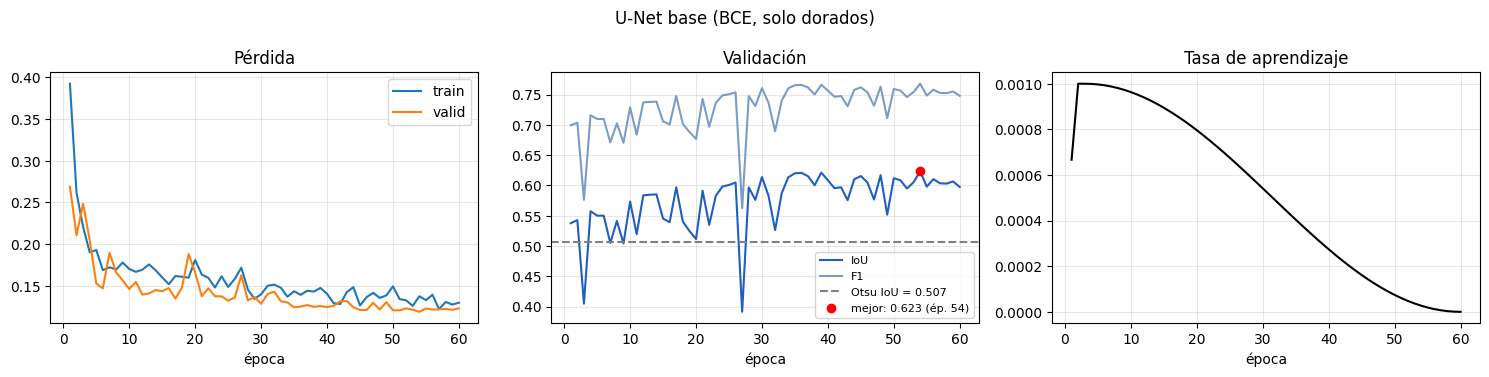

In [24]:
figura_curvas(historial, 'U-Net base (BCE, solo dorados)', linea_base_otsu.loc['valid', 'iou'],
              DIR_FIGURAS / 'f5_curvas_base_bce.png');

## 6. Mejor modelo vs. Otsu en validación (test se evalúa en la fase 7)

In [25]:
modelo, _, mejor_epoca = cargar_mejor_modelo(DIR_EXPERIMENTO, dispositivo)
acumulador_valid, _ = evaluar(modelo, cargadores['valid'], dispositivo)
comparacion = pd.DataFrame({'Otsu': linea_base_otsu.loc['valid'],
                            f'U-Net base (ép. {mejor_epoca})': acumulador_valid.metricas()}).T
comparacion.to_csv(DIR_RESULTADOS / 'f5_comparacion_valid.csv')
display(comparacion[['iou', 'f1', 'precision', 'recall', 'omision', 'comision']].round(3))
acumulador_valid.tabla_por_evento().to_csv(DIR_RESULTADOS / 'f5_por_evento_valid.csv')
acumulador_valid.tabla_por_evento()[['iou', 'f1', 'omision', 'comision']].round(3)

,iou,f1,precision,recall,omision,comision
Otsu,0.507,0.673,0.634,0.716,0.284,0.366
U-Net base (ép. 54),0.623,0.768,0.850,0.700,0.300,0.150


,iou,f1,omision,comision
Somalia,0.163,0.280,0.651,0.766
Ghana,0.416,0.588,0.581,0.014
Pakistan,0.476,0.645,0.174,0.470
Paraguay,0.544,0.705,0.388,0.169
Sri-Lanka,0.627,0.770,0.360,0.032
India,0.655,0.792,0.272,0.133
USA,0.663,0.798,0.267,0.125
Nigeria,0.753,0.859,0.220,0.044
Spain,0.758,0.862,0.138,0.137
Mekong,0.855,0.922,0.104,0.051


## 7. Predicciones de ejemplo (validación)

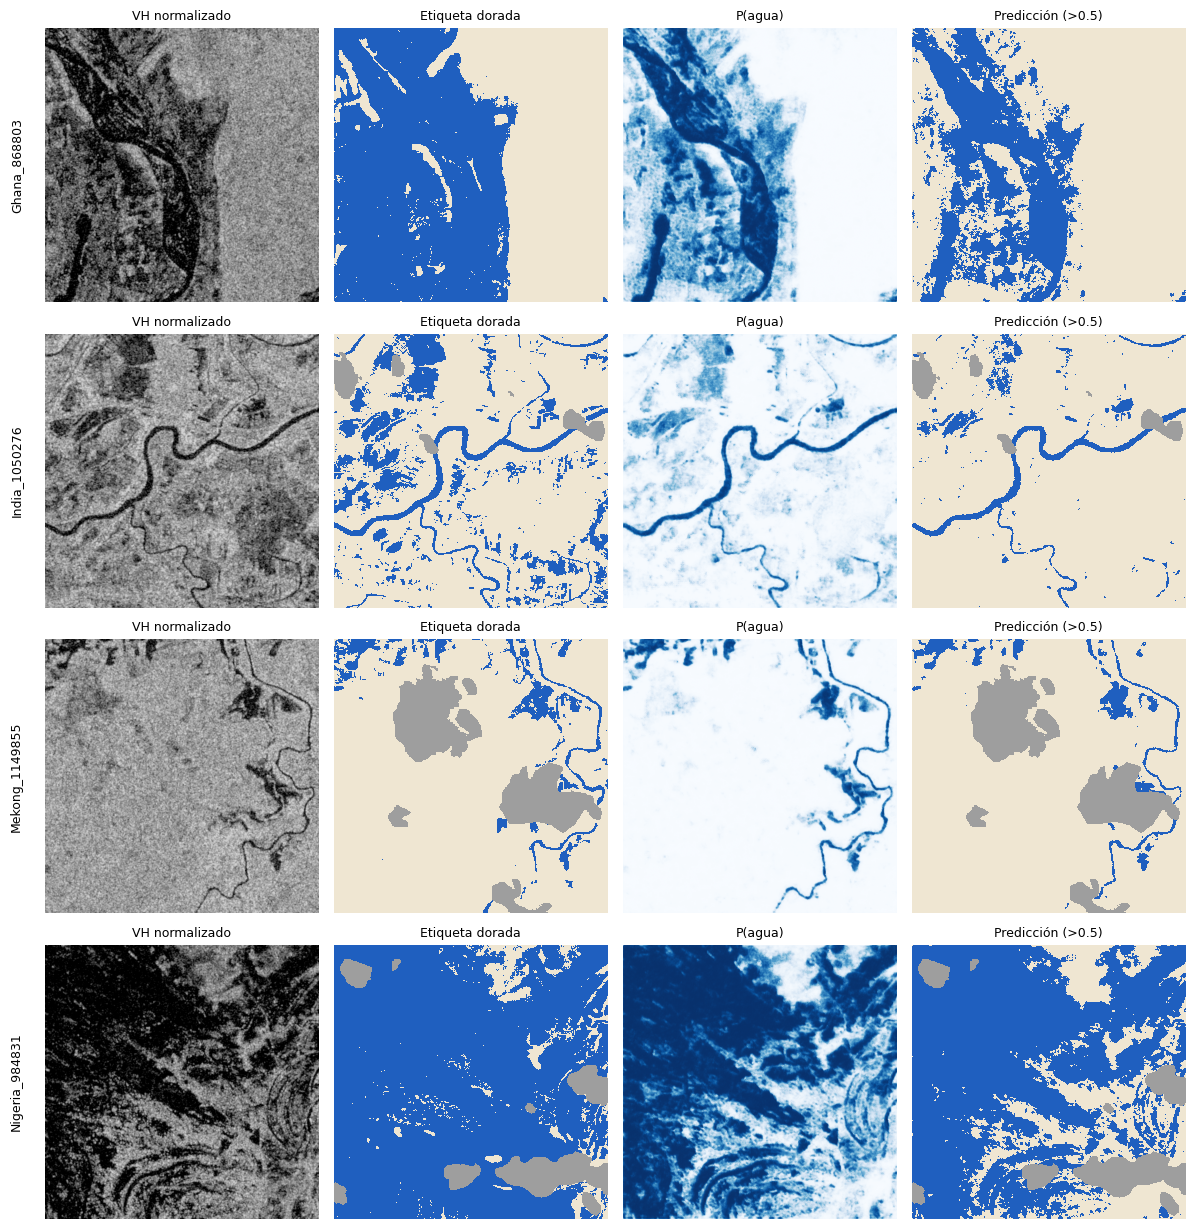

In [26]:
conjunto_valid = cargadores['valid'].dataset
eventos_vistos, ejemplos = set(), []
for i, id_chip in enumerate(conjunto_valid.ids_chips):
    evento = id_chip.split('_')[0]
    _, etiqueta = conjunto_valid.cache[i]
    if evento in eventos_vistos or (etiqueta == 1).mean() < 0.05:
        continue
    eventos_vistos.add(evento)
    imagen, etiqueta, _ = conjunto_valid[i]
    ejemplos.append((id_chip, imagen[1].numpy(), etiqueta.numpy(),
                     predecir_probabilidades(modelo, imagen, dispositivo).numpy()))
    if len(ejemplos) == 4:
        break
figura_predicciones(ejemplos, ruta_guardado=DIR_FIGURAS / 'f5_predicciones_base_bce.png');

## 8. Limpieza del Output
`ultimo.pt` solo sirve para reanudar (incluye el optimizador); el modelo final es `mejor.pt`. Lo borramos para que el Output pese menos.

In [27]:
(DIR_EXPERIMENTO / 'ultimo.pt').unlink(missing_ok=True)
!du -sh /kaggle/working/rnap_p2_inundaciones/*

2.5M	/kaggle/working/rnap_p2_inundaciones/figuras
30M	/kaggle/working/rnap_p2_inundaciones/resultados
192K	/kaggle/working/rnap_p2_inundaciones/src


In [28]:
!cd /kaggle/working && zip -rq fase5.zip rnap_p2_inundaciones/resultados rnap_p2_inundaciones/figuras
from IPython.display import FileLink
FileLink('fase5.zip')

/kaggle/working/fase5.zip